# Esse projeto, tem como objetivo testar e aprender sobre o algoritimo MONTE CARLO

MONTE CARLO - A Simulação de Monte Carlo é um tipo de algoritmo computacional que usa amostragem aleatória repetida para obter a probabilidade de ocorrência de uma série de resultados.

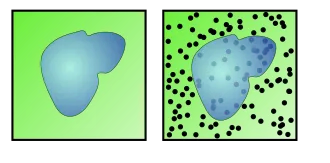

In [6]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dados = yf.download(
    "PETR4.SA",
    start="2021-01-01",
    end="2025-01-01",
    auto_adjust=False,
    progress=False
)

print(dados.head())
print(dados.shape)

dados.to_csv("petr4_historico.csv")


Price      Adj Close      Close     High        Low       Open    Volume
Ticker      PETR4.SA   PETR4.SA PETR4.SA   PETR4.SA   PETR4.SA  PETR4.SA
Date                                                                    
2021-01-04  7.806253  28.910000    29.18  28.530001  28.650000  74719700
2021-01-05  8.111377  30.040001    30.18  28.240000  28.900000  95181100
2021-01-06  8.127580  30.100000    30.90  30.049999  30.160000  96562500
2021-01-07  8.370597  31.000000    31.15  30.340000  30.340000  56171300
2021-01-08  8.402999  31.120001    31.76  30.350000  31.459999  67136300
(996, 6)


In [7]:
# Definindo os preços apartir da coluna close, pois é quando a ação está fechada e podemos ter uma métrica melhor sobre o valor da ação.

precos_petr4 = dados["Close"]["PETR4.SA"]

print(precos_petr4.head())

Date
2021-01-04    28.910000
2021-01-05    30.040001
2021-01-06    30.100000
2021-01-07    31.000000
2021-01-08    31.120001
Name: PETR4.SA, dtype: float64


In [8]:
# Iremos calcular a média diária da ação a partir da função pct_change, que irá realizar a formula X = Y-Z/Z.
# Dentro do nosso contexto, o dia 2021-01-04 teve um preço de 28.91, ele será o Z da fórmula, enquanto o dia 2021-01-05 teve um preço de 30.04, ele será o Y.
# Portanto, nossa fórmula seria X = 30.04-28.91/28.91-1 resultando eim 0,0391/100 = 3,91% de aumento.

retorno_diario = precos_petr4.pct_change().dropna()

print(retorno_diario.head())

Date
2021-01-05    0.039087
2021-01-06    0.001997
2021-01-07    0.029900
2021-01-08    0.003871
2021-01-11   -0.008355
Name: PETR4.SA, dtype: float64


In [9]:
# Agora iremos calcular a média e a volatidade (desvio padrão) dos retornos diário da ação PETR4.
# std() Standard Deviation, mean() média

media_retorno = retorno_diario.mean()
volatilidade_diaria = retorno_diario.std()

print(media_retorno)
print(volatilidade_diaria)

0.0005306724571371387
0.024422883969268963


In [10]:
# Agora vamos calcular a média anual, para conseguirmos ter uma visão mais ampla sobre a ação.
# Como em um ano tem cerca de 252 em média, apenas precisamos multiplicar pelo retorno diário.

dias_uteis = 252

retorno_anual = media_retorno * dias_uteis
volatilidade_anual = volatilidade_diaria * np.sqrt(dias_uteis)

print(f'{retorno_anual:.2%}')
print(f'\n{volatilidade_anual:.2%}')

13.37%

38.77%


In [11]:
# Definindo o capital inicial para a simulação

capital_inicial = 100_000
numeroDe_simulacoes = 10_000


np.random.seed(42)

In [12]:
# O módulo np.random é uma função da biblioteca Numpy para gerar números aleatórios
# O .normal() é uma função dentro desse módulo, que irá fazer uma geração de números aleatório dentro de um contexto de uma curva de Gauss ou também conhecida como gráfico de sino
# Dentro desse contexto financeiro, vários acontecimentos acontecem dentro dessa curva de Gauss

retornos_simulados = np.random.normal(
    loc=retorno_anual,
    scale=volatilidade_anual,
    size=numeroDe_simulacoes
)

retornos_simulados = np.maximum(retornos_simulados, -1)

# A variável retornos_simulados irá conter possíveis cenários de retorno para a PETR4

print(retornos_simulados)


[ 0.32630616  0.08012421  0.38483912 ... -0.13972273  0.3259384
  0.38355968]


In [13]:
# Irei definir os valores finais a partir da multiplicação do capital inicial sobre o retornos simulados
# O número 1 é uma representação do capital inicial, se você nem perder e nem ganhar, ainda mantem 100% do seu capital inicial
# Então, o capital inicial + retorno
# EX: retorno = 10% = 0.10 + capital inicial = 100.000 = 1 = 1.10


valores_finais = capital_inicial * (1 + retornos_simulados)

print(retornos_simulados[:5])
print(valores_finais[:5])

[0.32630616 0.08012421 0.38483912 0.72421006 0.0429479 ]
[132630.61640137 108012.42149113 138483.91238977 172421.00591656
 104294.7899921 ]


In [14]:
# Criarei uma análise das possiblidades a partir do valor final resgatado da útlima célula

valor_medio = np.mean(valores_finais)
valor_minimo = np.min(valores_finais)
valor_maximo = np.max(valores_finais)
probabilidade_perda = np.mean(valores_finais < capital_inicial)

print(f"Valor médio final: R$ {valor_medio:,.2f}")
print(f"Menor valor simulado: R$ {valor_minimo:,.2f}")
print(f"Maior valor simulado: R$ {valor_maximo:,.2f}")
print(f"Probabilidade de perda: {probabilidade_perda:.2%}")

Valor médio final: R$ 113,311.19
Menor valor simulado: R$ 0.00
Maior valor simulado: R$ 265,593.68
Probabilidade de perda: 36.54%


In [16]:
valor_medio = np.mean(valores_finais)
probabilidade_perda = np.mean(valores_finais < capital_inicial)

print(f"Valor médio final: R$ {valor_medio:,.2f}")
print(f"Probabilidade de perda: {probabilidade_perda:.2%}")

Valor médio final: R$ 113,311.19
Probabilidade de perda: 36.54%


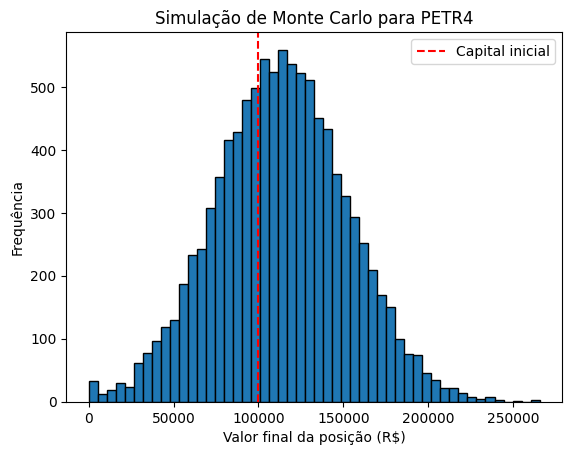

In [15]:
# Criarei agora um gráfico com a biblioteca matplotlib
#

plt.hist(valores_finais, bins=50, edgecolor="black")

plt.axvline(
    capital_inicial,
    color="red",
    linestyle="--",
    label="Capital inicial"
)

plt.title("Simulação de Monte Carlo para PETR4")
plt.xlabel("Valor final da posição (R$)")
plt.ylabel("Frequência")
plt.legend()
plt.show()

| Elemento                   | Interpretação                                    |
| -------------------------- | ------------------------------------------------ |
| **Eixo horizontal**        | Possíveis valores finais do investimento.        |
| **Eixo vertical**          | Quantidade de simulações em cada faixa de valor. |
| **Linha vermelha**         | Capital inicialmente investido.                  |
| **Barras à esquerda**      | Cenários de perda.                               |
| **Barras à direita**       | Cenários de ganho.                               |
| **Maior concentração**     | Faixa de valores mais frequente nas simulações.  |
| **Distribuição espalhada** | Maior incerteza e volatilidade.                  |

#Teste de Algoritimo Monte Carlo
##Com múltiplas ações

In [17]:
ativos = [
    "PETR4.SA",
    "VALE3.SA",
    "ITUB4.SA",
    "WEGE3.SA"
]

# Pesos de cada ativo dentro da carteira
pesos = pd.Series({
    "PETR4.SA": 0.25,
    "VALE3.SA": 0.25,
    "ITUB4.SA": 0.25,
    "WEGE3.SA": 0.25
})

# Baixa os dados históricos utilizando a biblioteca YFinance
dados = yf.download(
    ativos,
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

# Seleciona somente os preços de fechamento
precos = dados["Close"]

# Remove dias com dados ausentes
precos = precos.dropna()

# Calcula os retornos diários de cada ação
retornos = precos.pct_change().dropna()

# Garante que os pesos estejam na mesma ordem das colunas
pesos = pesos[retornos.columns]

# Verifica se os pesos somam 100%
if not np.isclose(pesos.sum(), 1):
    raise ValueError("Os pesos devem somar 100%.")

# Calcula o retorno diário da carteira
retorno_carteira = retornos.dot(pesos)

# Calcula média e volatilidade da carteira
media_diaria = retorno_carteira.mean()
volatilidade_diaria = retorno_carteira.std()

# Anualiza os valores
dias_uteis = 252

media_anual = media_diaria * dias_uteis
volatilidade_anual = volatilidade_diaria * np.sqrt(dias_uteis)

print(f"Média diária da carteira: {media_diaria:.2%}")
print(f"Volatilidade diária da carteira: {volatilidade_diaria:.2%}")
print(f"Média anualizada: {media_anual:.2%}")
print(f"Volatilidade anualizada: {volatilidade_anual:.2%}")


correlacao = retornos.corr()

print("\nMatriz de correlação:")
print(correlacao)


Média diária da carteira: 0.07%
Volatilidade diária da carteira: 1.22%
Média anualizada: 18.17%
Volatilidade anualizada: 19.43%

Matriz de correlação:
Ticker    ITUB4.SA  PETR4.SA  VALE3.SA  WEGE3.SA
Ticker                                          
ITUB4.SA  1.000000  0.344601  0.215570  0.214925
PETR4.SA  0.344601  1.000000  0.242741  0.152044
VALE3.SA  0.215570  0.242741  1.000000  0.159717
WEGE3.SA  0.214925  0.152044  0.159717  1.000000


In [18]:
capital_inicial = 100_000
numero_simulacoes = 10_000

retornos_simulados = np.random.normal(
    loc=media_anual,
    scale=volatilidade_anual,
    size=numero_simulacoes
)

valores_finais = capital_inicial * (1 + retornos_simulados)

print(f"\nValor médio final: R$ {np.mean(valores_finais):,.2f}")
print(f"Probabilidade de perda: {np.mean(valores_finais < capital_inicial):.2%}")


Valor médio final: R$ 118,430.93
Probabilidade de perda: 16.70%


In [19]:
valores_finais = capital_inicial * (1 + retornos_simulados)

print(retornos_simulados[:5])
print(valores_finais[:5])

[0.0498473  0.12232074 0.06560779 0.20313402 0.41429291]
[104984.73034244 112232.07398756 106560.7788559  120313.40205301
 141429.29112424]


In [20]:
# Criarei uma análise das possiblidades a partir do valor final resgatado da útlima célula

valor_medio = np.mean(valores_finais)
valor_minimo = np.min(valores_finais)
valor_maximo = np.max(valores_finais)
probabilidade_perda = np.mean(valores_finais < capital_inicial)

print(f"Valor médio final: R$ {valor_medio:,.2f}")
print(f"Menor valor simulado: R$ {valor_minimo:,.2f}")
print(f"Maior valor simulado: R$ {valor_maximo:,.2f}")
print(f"Probabilidade de perda: {probabilidade_perda:.2%}")

Valor médio final: R$ 118,430.93
Menor valor simulado: R$ 43,238.12
Maior valor simulado: R$ 205,197.12
Probabilidade de perda: 16.70%


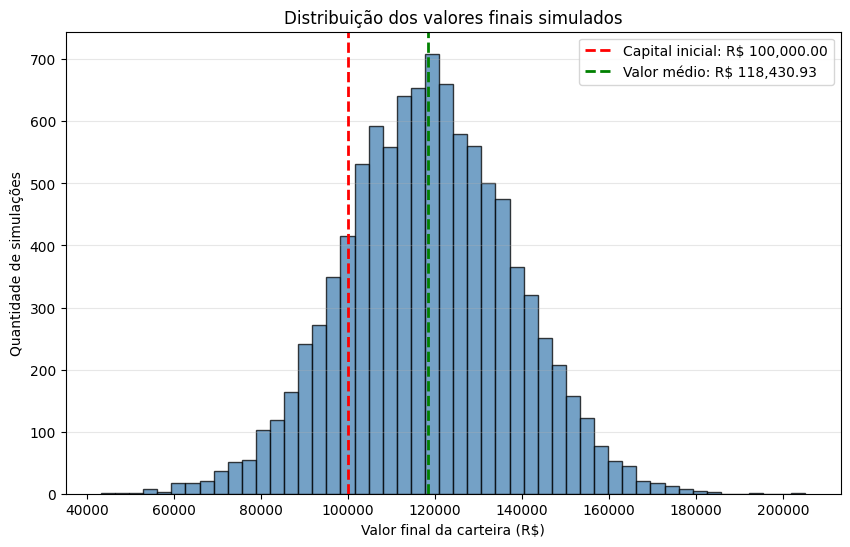

In [22]:
plt.figure(figsize=(10, 6))

plt.hist(
    valores_finais,
    bins=50,
    color="steelblue",
    edgecolor="black",
    alpha=0.75
)

# Linha do capital inicial
plt.axvline(
    capital_inicial,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Capital inicial: R$ {capital_inicial:,.2f}"
)

# Linha do valor médio simulado
plt.axvline(
    valor_medio,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Valor médio: R$ {valor_medio:,.2f}"
)

plt.title("Distribuição dos valores finais simulados")
plt.xlabel("Valor final da carteira (R$)")
plt.ylabel("Quantidade de simulações")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()


#Como interpretar o gráfico


*   A linha vermelha representa o capital inicial.
*   A linha verde representa o valor médio encontrado nas simulações.
*   As barras à esquerda da linha vermelha representam cenários de perda.
*   As barras à direita representam cenários de ganho.
*   As barras mais altas indicam faixas de valores que apareceram com maior frequência.

